In [1]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")
ROOT = Path("/content/drive/MyDrive/vhap")

needed = [
    ROOT / "data" / "splits.json",
    ROOT / "data" / "ueyes_web" / "images",
    ROOT / "src" / "dataset.py",
    ROOT / "models" / "transalnet_pretrained" / "TranSalNet_Res.pth",
    ROOT / "models" / "transalnet_pretrained" / "resnet50-0676ba61.pth",
]
for p in needed:
    print(("OK " if p.exists() else "MISSING "), p)

Mounted at /content/drive
OK  /content/drive/MyDrive/vhap/data/splits.json
OK  /content/drive/MyDrive/vhap/data/ueyes_web/images
OK  /content/drive/MyDrive/vhap/src/dataset.py
OK  /content/drive/MyDrive/vhap/models/transalnet_pretrained/TranSalNet_Res.pth
OK  /content/drive/MyDrive/vhap/models/transalnet_pretrained/resnet50-0676ba61.pth


In [2]:
import shutil
from pathlib import Path

local = Path("/content/ueyes_web")
if not local.exists():
    shutil.copytree(ROOT / "data" / "ueyes_web", local)

%cd /content
!git clone https://github.com/LJOVO/TranSalNet.git
!mkdir -p /content/TranSalNet/pretrained_models /content/checkpoints
!cp /content/drive/MyDrive/vhap/models/transalnet_pretrained/*.pth /content/TranSalNet/pretrained_models/

/content
Cloning into 'TranSalNet'...
remote: Enumerating objects: 58, done.
remote: Counting objects: 100% (15/15), done.
remote: Compressing objects: 100% (12/12), done.
remote: Total 58 (delta 6), reused 3 (delta 3), pack-reused 43 (from 1)
Receiving objects: 100% (58/58), 3.14 MiB | 27.75 MiB/s, done.
Resolving deltas: 100% (9/9), done.


In [3]:
from pathlib import Path
p = Path("/content/TranSalNet/utils/resnet.py")
old = "state_dict = torch.load(r'pretrained_models/resnet50-0676ba61.pth')"
new = "state_dict = torch.load(r'pretrained_models/resnet50-0676ba61.pth', weights_only=False)"
text = p.read_text()
if old in text:
    p.write_text(text.replace(old, new, 1))
    print("patched")
else:
    print("already patched or the line differs")

%cd /content/TranSalNet

patched
/content/TranSalNet


In [4]:
import json, random, sys
import numpy as np
import torch
from torch.utils.data import DataLoader

sys.path.append(str(ROOT / "src"))
from dataset import UEyesWebDataset
from TranSalNet_Res import TranSalNet

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

splits = json.loads((ROOT / "data" / "splits.json").read_text())
assert set(splits["train"]).isdisjoint(splits["val"])
assert set(splits["train"]).isdisjoint(splits["test"])
assert set(splits["val"]).isdisjoint(splits["test"])

train_ds = UEyesWebDataset("/content/ueyes_web", splits["train"], augment=True)
val_ds = UEyesWebDataset("/content/ueyes_web", splits["val"], augment=False)
generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_ds, batch_size=4, shuffle=True, num_workers=0, generator=generator)
val_loader = DataLoader(val_ds, batch_size=4, shuffle=False, num_workers=0)

device = "cuda" if torch.cuda.is_available() else "cpu"
model = TranSalNet()
state = torch.load("pretrained_models/TranSalNet_Res.pth", map_location=device, weights_only=False)
model.load_state_dict(state)
model = model.to(device)
print("loaded SALICON weights on", device, "train", len(train_ds), "val", len(val_ds))

loaded SALICON weights on cuda train 346 val 74


In [5]:
import torch.nn.functional as F

EPS = 1e-8
W_KL, W_CC, W_NSS = 10.0, -2.0, -1.0

def kl_div(pred, gt):
    p = pred / (pred.sum(dim=(1, 2, 3), keepdim=True) + EPS)
    g = gt / (gt.sum(dim=(1, 2, 3), keepdim=True) + EPS)
    return (g * torch.log(EPS + g / (p + EPS))).sum(dim=(1, 2, 3)).mean()

def cc_metric(pred, gt):
    dims = (1, 2, 3)
    p = (pred - pred.mean(dim=dims, keepdim=True)) / (pred.std(dim=dims, keepdim=True) + EPS)
    g = (gt - gt.mean(dim=dims, keepdim=True)) / (gt.std(dim=dims, keepdim=True) + EPS)
    return (p * g).mean(dim=dims).mean()

def nss_metric(pred, fix):
    dims = (1, 2, 3)
    p = (pred - pred.mean(dim=dims, keepdim=True)) / (pred.std(dim=dims, keepdim=True) + EPS)
    return ((p * fix).sum(dim=dims) / (fix.sum(dim=dims) + EPS)).mean()

def saliency_loss(pred, sal_dist, sal_01, fix):
    pred = pred.float()
    loss = W_KL * kl_div(pred, sal_dist.float()) + W_CC * cc_metric(pred, sal_01.float())
    loss = loss + W_NSS * nss_metric(pred, fix.float())
    return loss

In [6]:
import csv, shutil
from pathlib import Path

STAGE_A_EPOCHS = 5
STAGE_B_EPOCHS = 45
PATIENCE = 8

def set_stage_a(model):
    model.train()
    model.encoder.eval()
    for p in model.encoder.parameters():
        p.requires_grad = False
    for p in model.decoder.parameters():
        p.requires_grad = True

def set_stage_b(model):
    for p in model.parameters():
        p.requires_grad = True
    model.train()

def count_trainable(model):
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    print(f"trainable {trainable:,} / {total:,}")

log_path = ROOT / "results" / "train_log.csv"
log_path.parent.mkdir(parents=True, exist_ok=True)
drive_best = ROOT / "models" / "checkpoints" / "best.pt"
drive_best.parent.mkdir(parents=True, exist_ok=True)
local_best = Path("/content/checkpoints/best.pt")

state = {"best_cc": -1.0, "bad": 0}
if not log_path.exists():
    with log_path.open("w", newline="") as f:
        csv.writer(f).writerow(["epoch", "stage", "train_loss", "train_cc", "val_cc", "val_kl", "val_nss", "lr"])

In [7]:
scaler = torch.amp.GradScaler("cuda", enabled=(device == "cuda"))

def train_one_epoch(optimizer, stage_name):
    if stage_name == "A":
        model.train()
        model.encoder.eval()
    else:
        model.train()
    total_loss, total_cc, seen = 0.0, 0.0, 0
    for batch in train_loader:
        img = batch["image"].to(device)
        sal_dist = batch["saliency_dist"].to(device)
        sal_01 = batch["saliency_01"].to(device)
        fix = batch["fixation"].to(device)
        optimizer.zero_grad(set_to_none=True)
        with torch.amp.autocast("cuda", enabled=(device == "cuda")):
            pred = model(img)
        loss = saliency_loss(pred, sal_dist, sal_01, fix)
        if not torch.isfinite(loss):
            raise RuntimeError("Loss became NaN. Stop. Do not keep training.")
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer)
        scaler.update()
        total_loss += loss.item() * img.size(0)
        total_cc += cc_metric(pred.float(), sal_01.float()).item() * img.size(0)
        seen += img.size(0)
    return total_loss / seen, total_cc / seen

@torch.no_grad()
def evaluate():
    model.eval()
    totals = {"cc": 0.0, "kl": 0.0, "nss": 0.0}
    seen = 0
    for batch in val_loader:
        img = batch["image"].to(device)
        sal_dist = batch["saliency_dist"].to(device)
        sal_01 = batch["saliency_01"].to(device)
        fix = batch["fixation"].to(device)
        pred = model(img).float()
        n = img.size(0)
        totals["cc"] += cc_metric(pred, sal_01).item() * n
        totals["kl"] += kl_div(pred, sal_dist).item() * n
        totals["nss"] += nss_metric(pred, fix).item() * n
        seen += n
    return totals["cc"] / seen, totals["kl"] / seen, totals["nss"] / seen

def save_best(epoch_label, stage_name, val_cc, lr):
    payload = {
        "model": model.state_dict(),
        "epoch": epoch_label,
        "stage": stage_name,
        "val_cc": val_cc,
        "seed": SEED,
        "split_file": "data/splits.json",
        "loss_weights": {"kl": W_KL, "cc": W_CC, "nss": W_NSS},
        "lr": lr,
        "batch_size": 4,
        "input": "pad 384x288, divide by 255, no ImageNet normalization",
        "torch": torch.__version__,
    }
    torch.save(payload, local_best)
    shutil.copy2(local_best, drive_best)

def run_stage(stage_name, max_epochs, patience, optimizer, scheduler):
    state["bad"] = 0
    for epoch in range(1, max_epochs + 1):
        train_loss, train_cc = train_one_epoch(optimizer, stage_name)
        val_cc, val_kl, val_nss = evaluate()
        lr = optimizer.param_groups[0]["lr"]
        if scheduler is not None:
            scheduler.step(val_cc)
        with log_path.open("a", newline="") as f:
            csv.writer(f).writerow([f"{stage_name}{epoch}", stage_name, f"{train_loss:.4f}", f"{train_cc:.4f}", f"{val_cc:.4f}", f"{val_kl:.4f}", f"{val_nss:.4f}", lr])
        print(f"{stage_name}{epoch:02d}  loss {train_loss:.3f}  train_cc {train_cc:.4f}  val_cc {val_cc:.4f}  val_kl {val_kl:.3f}  val_nss {val_nss:.3f}  lr {lr:.1e}")
        if train_cc - val_cc > 0.15:
            print("  gap is large: overfitting. Do not add flips.")
        if val_cc > state["best_cc"]:
            state["best_cc"] = val_cc
            state["bad"] = 0
            save_best(f"{stage_name}{epoch}", stage_name, val_cc, lr)
            print("  saved best.pt")
        else:
            state["bad"] += 1
            if state["bad"] >= patience:
                print("early stopping")
                break

set_stage_a(model)
count_trainable(model)
opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=1e-4, weight_decay=1e-4)
run_stage("A", STAGE_A_EPOCHS, patience=5, optimizer=opt, scheduler=None)

set_stage_b(model)
count_trainable(model)
opt = torch.optim.AdamW(model.parameters(), lr=1e-5, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=3)
run_stage("B", STAGE_B_EPOCHS, patience=PATIENCE, optimizer=opt, scheduler=sched)
print("best validation CC", round(state["best_cc"], 4))

trainable 49,002,945 / 72,510,977
A01  loss 5.362  train_cc 0.6128  val_cc 0.6179  val_kl 0.807  val_nss 1.687  lr 1.0e-04
  saved best.pt
A02  loss 3.986  train_cc 0.6698  val_cc 0.6300  val_kl 0.796  val_nss 1.732  lr 1.0e-04
  saved best.pt
A03  loss 3.246  train_cc 0.7053  val_cc 0.6287  val_kl 0.787  val_nss 1.731  lr 1.0e-04
A04  loss 2.620  train_cc 0.7349  val_cc 0.6190  val_kl 0.794  val_nss 1.680  lr 1.0e-04
A05  loss 2.115  train_cc 0.7586  val_cc 0.6213  val_kl 0.806  val_nss 1.707  lr 1.0e-04
trainable 72,510,977 / 72,510,977
B01  loss 3.066  train_cc 0.7127  val_cc 0.6217  val_kl 0.793  val_nss 1.709  lr 1.0e-05
B02  loss 1.785  train_cc 0.7725  val_cc 0.6198  val_kl 0.793  val_nss 1.712  lr 1.0e-05
  gap is large: overfitting. Do not add flips.
B03  loss 1.157  train_cc 0.8031  val_cc 0.6172  val_kl 0.797  val_nss 1.705  lr 1.0e-05
  gap is large: overfitting. Do not add flips.
B04  loss 0.754  train_cc 0.8195  val_cc 0.6131  val_kl 0.817  val_nss 1.699  lr 1.0e-05
  gap

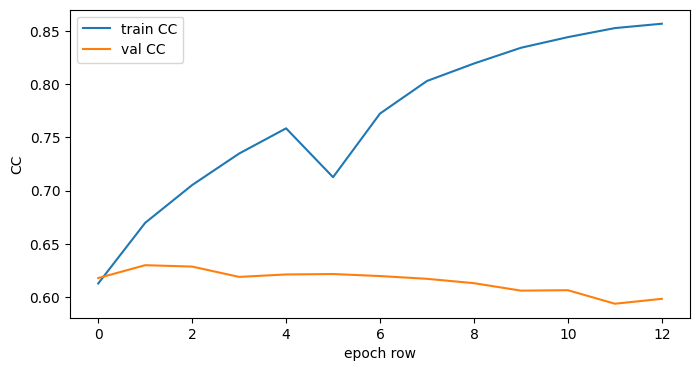

epoch stage  train_loss  train_cc  val_cc  val_kl  val_nss       lr
   B1     B      3.0660    0.7127  0.6217  0.7928   1.7086 0.000010
   B2     B      1.7853    0.7725  0.6198  0.7927   1.7124 0.000010
   B3     B      1.1571    0.8031  0.6172  0.7971   1.7054 0.000010
   B4     B      0.7536    0.8195  0.6131  0.8165   1.6987 0.000010
   B5     B      0.3549    0.8343  0.6061  0.8245   1.6801 0.000010
   B6     B      0.0745    0.8443  0.6065  0.8303   1.6854 0.000005
   B7     B     -0.1216    0.8528  0.5938  0.8573   1.6487 0.000005
   B8     B     -0.2712    0.8569  0.5984  0.8508   1.6609 0.000005
best file /content/drive/MyDrive/vhap/models/checkpoints/best.pt exists


In [8]:
import pandas as pd
import matplotlib.pyplot as plt

log = pd.read_csv(log_path)
plt.figure(figsize=(8, 4))
plt.plot(log["train_cc"], label="train CC")
plt.plot(log["val_cc"], label="val CC")
plt.xlabel("epoch row")
plt.ylabel("CC")
plt.legend()
plt.show()
print(log.tail(8).to_string(index=False))
print("best file", drive_best, "exists" if drive_best.exists() else "MISSING")